# Recomendação de livros

Recomendação reaproveitando as representações do `comparacao_modelos.ipynb`: BoW, TF-IDF, Word2Vec e BERT/MiniLM e depois demonstra e avalia.

In [1]:
import re
import unicodedata
import warnings
from difflib import get_close_matches
from pathlib import Path
from typing import Callable, Optional, Sequence, Union

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

CAMINHO_PADRAO = Path("gutenberg_books.csv")
MODELOS_VALIDOS = ("bow", "tfidf", "word2vec", "bert")
RRF_K = 60

Regra de gênero copiada da `comparacao_modelos.ipynb`.

In [2]:
def normalizar_para_regra(texto):
    texto = "" if pd.isna(texto) else str(texto).lower()
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto if not unicodedata.combining(c))


def identificar_genero(subjects):
    s = normalizar_para_regra(subjects)

    regras = [
        (
            "Ficção científica/fantasia",
            [
                r"science fiction",
                r"fantasy fiction",
                r"fantasy stories",
                r"utopias?",
                r"dystopias?",
            ],
        ),
        (
            "Mistério/policial",
            [
                r"detective and mystery stories",
                r"detective stories",
                r"mystery fiction",
                r"crime fiction",
                r"police stories",
                r"suspense fiction",
            ],
        ),
        (
            "Terror/gótico",
            [
                r"horror fiction",
                r"horror tales?",
                r"ghost stories",
                r"gothic fiction",
                r"supernatural fiction",
                r"vampire fiction",
                r"paranormal fiction",
            ],
        ),
        (
            "Romance",
            [
                r"love stories",
                r"romance fiction",
                r"romantic fiction",
                r"courtship.{0,30}fiction",
            ],
        ),
        (
            "Guerra",
            [
                r"war stories",
                r"war fiction",
                r"military fiction",
                r"world war.{0,30}fiction",
            ],
        ),
        (
            "Aventura",
            [
                r"adventure stories",
                r"adventure fiction",
                r"sea stories",
                r"pirates.{0,30}fiction",
            ],
        ),
        (
            "Ficção histórica",
            [
                r"historical fiction",
                r"historical stories",
            ],
        ),
        (
            "Faroeste",
            [
                r"western stories",
                r"cowboy stories",
                r"western fiction",
            ],
        ),

        (
            "Romance de formação",
            [
                r"\bbildungsromans?\b",
            ],
        ),
        (
            "Ficção doméstica/familiar",
            [
                r"\bdomestic fiction\b",
            ],
        ),
        (
            "Ficção psicológica",
            [
                r"\bpsychological fiction\b",
            ],
        ),
        (
            "Humor",
            [
                r"\bhumorous stories?\b",
            ],
        ),
        (
            "Ficção didática",
            [
                r"\bdidactic fiction\b",
            ],
        ),
        (
            "Ficção autobiográfica",
            [
                r"\bautobiographical fiction\b",
            ],
        ),
        (
            "Ficção epistolar",
            [
                r"\bepistolary fiction\b",
            ],
        ),
        (
            "Ficção política",
            [
                r"\bpolitical fiction\b",
            ],
        ),
        (
            "Romance literário",
            [
                r"\bromances\b",
            ],
        ),
        (
            "Literatura infantil/juvenil",
            [
                r"\bjuvenile fiction\b",
                r"\bchildren['’]s stories\b",
            ],
        ),
        (
            "Poesia",
            [
                r"\bpoetry\b",
                r"\bpoems?\b",
                r"\bsonnets?\b",
            ],
        ),
    ]

    for genero, padroes in regras:
        if any(re.search(padrao, s) for padrao in padroes):
            return genero

    return np.nan

### Catálogo

In [3]:
def _chave_titulo(titulo: str) -> str:
    t = normalizar_para_regra(titulo)
    t = re.split(r"[;:]", t)[0]
    return re.sub(r"[^a-z0-9 ]", "", t).strip()


def _autor_legivel(autor) -> str:
    if pd.isna(autor):
        return ""
    partes = [p.strip() for p in str(autor).split(",")]
    if len(partes) >= 2 and not re.search(r"\d", partes[1]):
        return f"{partes[1]} {partes[0]}"
    return partes[0]


def carregar_catalogo(
    caminho: Union[str, Path, None] = None,
    coluna_texto: str = "text_final",
) -> pd.DataFrame:
    df = pd.read_csv(caminho or CAMINHO_PADRAO, dtype={"book_id": str})
    df["texto"] = df[coluna_texto].fillna("").astype(str).str.strip()
    df = df[df["texto"] != ""].reset_index(drop=True)
    df["genero"] = df["subjects"].apply(identificar_genero)
    df["autor_legivel"] = df["author"].apply(_autor_legivel)
    df["chave_titulo"] = df["title"].apply(_chave_titulo)
    return df

### Recomendador

Três entradas: consulta, livro semelhante, perfil

In [4]:
Modelo = Union[str, Sequence[str]]


class RecomendadorLivros:

    def __init__(
        self,
        df: pd.DataFrame,
        modelos: Sequence[str] = ("tfidf", "bert"),
        coluna_bert: str = "summary",
        encoder_bert: Optional[Callable[[list], np.ndarray]] = None,
        rrf_k: int = RRF_K,
    ):
        invalidos = [m for m in modelos if m not in MODELOS_VALIDOS]
        if invalidos:
            raise ValueError(f"Modelos inválidos: {invalidos}. Use {MODELOS_VALIDOS}.")

        self.df = df.reset_index(drop=True)
        self.rrf_k = rrf_k
        self.modelos: list = []
        self._X: dict = {}
        self._coluna_bert = coluna_bert
        self._encoder_bert = encoder_bert

        textos = self.df["texto"].tolist()


        self._tfidf = TfidfVectorizer()
        self._X_tfidf = self._tfidf.fit_transform(textos)
        self._termos = self._tfidf.get_feature_names_out()

        for nome in modelos:
            if nome == "tfidf":
                self._X["tfidf"] = self._X_tfidf
            elif nome == "bow":
                self._bow = CountVectorizer()
                self._X["bow"] = self._bow.fit_transform(textos)
            elif nome == "word2vec":
                self._construir_word2vec(textos)
            elif nome == "bert":
                if not self._construir_bert():
                    continue
            self.modelos.append(nome)

        if not self.modelos:
            raise RuntimeError("Nenhuma representação pôde ser construída.")

    def _construir_word2vec(self, textos):
        from gensim.models import Word2Vec

        tokens = [t.lower().split() for t in textos]
        self._w2v = Word2Vec(
            sentences=tokens, vector_size=100, window=5, min_count=2,
            workers=1, sg=1, epochs=20, seed=42,
        )
        self._X["word2vec"] = np.array([self._media_w2v(t) for t in tokens])

    def _media_w2v(self, tokens):
        vetores = [self._w2v.wv[t] for t in tokens if t in self._w2v.wv]
        if not vetores:
            return np.zeros(self._w2v.vector_size)
        return np.mean(vetores, axis=0)

    def _construir_bert(self) -> bool:
        if self._encoder_bert is None:
            try:
                from sentence_transformers import SentenceTransformer
            except ImportError:
                warnings.warn(
                    "sentence-transformers não está instalado: o modelo 'bert' foi "
                    "ignorado. Instale com: pip install sentence-transformers"
                )
                return False
            modelo = SentenceTransformer("all-MiniLM-L6-v2")
            self._encoder_bert = lambda frases: modelo.encode(
                frases, show_progress_bar=False, convert_to_numpy=True
            )
        textos = self.df[self._coluna_bert].fillna("").astype(str).tolist()
        self._X["bert"] = np.asarray(self._encoder_bert(textos))
        return True

    @staticmethod
    def _limpar_consulta(consulta: str) -> str:
        c = re.sub(r"[^\w\s]", " ", consulta.lower())
        return re.sub(r"\s+", " ", c).strip()

    def _vetor_consulta(self, nome: str, consulta: str):
        limpa = self._limpar_consulta(consulta)
        if nome == "tfidf":
            return self._tfidf.transform([limpa])
        if nome == "bow":
            return self._bow.transform([limpa])
        if nome == "word2vec":
            vec = self._media_w2v(limpa.split())
            return vec.reshape(1, -1) if np.linalg.norm(vec) > 0 else None
        if nome == "bert":
            return np.asarray(self._encoder_bert([consulta]))
        raise ValueError(nome)
    def _resolver_modelos(self, modelo: Modelo) -> list:
        if modelo == "hibrido":
            return list(self.modelos)
        escolhidos = [modelo] if isinstance(modelo, str) else list(modelo)
        ausentes = [m for m in escolhidos if m not in self.modelos]
        if ausentes:
            raise ValueError(f"Modelo(s) não construído(s): {ausentes}. Disponíveis: {self.modelos}")
        return escolhidos

    def _ranquear(self, vetores: dict, escolhidos: list, pool: np.ndarray, top_n: int):
        rrf = np.zeros(len(pool))
        cossenos: dict = {}
        usados = 0
        for nome in escolhidos:
            vec = vetores.get(nome)
            if vec is None:
                continue
            sims = cosine_similarity(vec, self._X[nome][pool]).ravel()
            if sims.max() <= 0:
                continue
            cossenos[nome] = sims
            ordem = np.argsort(-sims, kind="stable")
            posicao = np.empty(len(pool), dtype=int)
            posicao[ordem] = np.arange(1, len(pool) + 1)
            positivo = sims > 0
            rrf[positivo] += 1.0 / (self.rrf_k + posicao[positivo])
            usados += 1
        if usados == 0:
            return []

        score = rrf if len(escolhidos) > 1 else cossenos[escolhidos[0]]
        ordem_final = np.argsort(-score, kind="stable")

        resultado, vistos = [], set()
        for j in ordem_final:
            if score[j] <= 0:
                break
            idx = pool[j]
            chave = self.df.at[idx, "chave_titulo"]
            if chave in vistos:
                continue
            vistos.add(chave)
            resultado.append((idx, float(score[j]), {m: float(s[j]) for m, s in cossenos.items()}))
            if len(resultado) == top_n:
                break
        return resultado

    def _montar_pool(self, excluir: Sequence[int] = (), genero: Optional[str] = None,
                     apenas_rotulados: bool = False) -> np.ndarray:
        mascara = np.ones(len(self.df), dtype=bool)
        mascara[list(excluir)] = False
        if genero is not None:
            mascara &= (self.df["genero"] == genero).to_numpy()
        if apenas_rotulados:
            mascara &= self.df["genero"].notna().to_numpy()
        return np.flatnonzero(mascara)

    def _termos_em_comum(self, vec_tfidf, idx: int, n: int = 5) -> str:
        contrib = csr_matrix(vec_tfidf).multiply(self._X_tfidf[idx]).tocoo()
        if contrib.nnz == 0:
            return ""
        top = np.argsort(-contrib.data)[:n]
        return ", ".join(self._termos[contrib.col[top]])

    def _formatar(self, resultado, vec_tfidf, escolhidos) -> pd.DataFrame:
        colunas = ["book_id", "title", "autor", "genero", "score", "termos_em_comum"]
        linhas = []
        for idx, score, sims in resultado:
            linha = {
                "book_id": self.df.at[idx, "book_id"],
                "title": self.df.at[idx, "title"],
                "autor": self.df.at[idx, "autor_legivel"],
                "genero": self.df.at[idx, "genero"],
                "score": round(score, 4),
                "termos_em_comum": self._termos_em_comum(vec_tfidf, idx),
            }
            for m in escolhidos:
                linha[f"cos_{m}"] = round(sims[m], 4) if m in sims else np.nan
            linhas.append(linha)
        return pd.DataFrame(linhas, columns=colunas + [f"cos_{m}" for m in escolhidos])


    def recomendar_por_consulta(self, consulta: str, top_n: int = 5,
                                modelo: Modelo = "hibrido",
                                genero: Optional[str] = None) -> pd.DataFrame:
        escolhidos = self._resolver_modelos(modelo)
        vetores = {m: self._vetor_consulta(m, consulta) for m in escolhidos}
        pool = self._montar_pool(genero=genero)
        resultado = self._ranquear(vetores, escolhidos, pool, top_n)
        vec_expl = self._tfidf.transform([self._limpar_consulta(consulta)])
        return self._formatar(resultado, vec_expl, escolhidos)


    def localizar(self, livro: str) -> int:
        """Aceita book_id exato ou parte do título (sem diferenciar maiúsculas)."""
        livro = str(livro).strip()
        igual = self.df.index[self.df["book_id"] == livro]
        if len(igual):
            return int(igual[0])
        achados = self.df.index[self.df["title"].str.contains(livro, case=False, regex=False)]
        if len(achados):
            return int(achados[0])
        sugestoes = get_close_matches(livro, self.df["title"].tolist(), n=3, cutoff=0.4)
        raise ValueError(f"Livro não encontrado: {livro!r}. Parecidos: {sugestoes}")

    def _indices_da_obra(self, idx: int) -> list:
        chave = self.df.at[idx, "chave_titulo"]
        return self.df.index[self.df["chave_titulo"] == chave].tolist()

    def recomendar_similares(self, livro: str, top_n: int = 5,
                             modelo: Modelo = "hibrido",
                             genero: Optional[str] = None) -> pd.DataFrame:
        idx = self.localizar(livro)
        escolhidos = self._resolver_modelos(modelo)
        vetores = {m: self._X[m][idx:idx + 1] for m in escolhidos}
        pool = self._montar_pool(excluir=self._indices_da_obra(idx), genero=genero)
        resultado = self._ranquear(vetores, escolhidos, pool, top_n)
        return self._formatar(resultado, self._X_tfidf[idx], escolhidos)

    def recomendar_por_perfil(self, livros: Sequence[str], top_n: int = 5,
                              modelo: Modelo = "hibrido",
                              genero: Optional[str] = None) -> pd.DataFrame:
        indices = [self.localizar(l) for l in livros]
        escolhidos = self._resolver_modelos(modelo)
        vetores = {}
        for m in escolhidos:
            X = self._X[m][indices]
            vetores[m] = np.asarray(X.mean(axis=0)).reshape(1, -1)
        excluir = sorted({j for i in indices for j in self._indices_da_obra(i)})
        pool = self._montar_pool(excluir=excluir, genero=genero)
        resultado = self._ranquear(vetores, escolhidos, pool, top_n)
        vec_expl = np.asarray(self._X_tfidf[indices].mean(axis=0)).reshape(1, -1)
        return self._formatar(resultado, vec_expl, escolhidos)

    def avaliar_por_genero(self, modelos: Optional[Sequence[Modelo]] = None,
                           ks: Sequence[int] = (3, 5)) -> pd.DataFrame:
        """
        Avaliação sem juízes humanos: para cada livro com gênero conhecido, pede
        os livros mais parecidos (entre os que também têm gênero) e considera
        'relevante' o que tem o MESMO gênero.  Reporta Precision@k e MRR e compara
        com o acaso. É uma aproximação: o rótulo de gênero vem de regex sobre
        'subjects' (ver recomendacao.md, seção de limitações).
        """
        modelos = list(modelos) if modelos else [[m] for m in self.modelos]
        if len(self.modelos) > 1 and "hibrido" not in modelos:
            modelos.append("hibrido")

        rotulados = self.df["genero"].notna().to_numpy()
        contagem = self.df["genero"].value_counts()
        sementes = [i for i in np.flatnonzero(rotulados)
                    if len({self.df.at[j, "chave_titulo"]
                            for j in self.df.index[self.df["genero"] == self.df.at[i, "genero"]]
                            if self.df.at[j, "chave_titulo"] != self.df.at[i, "chave_titulo"]}) >= 1]

        n_rot = int(rotulados.sum())
        acaso = np.mean([
            (contagem[self.df.at[i, "genero"]] - 1) / (n_rot - 1) for i in sementes
        ])

        k_max = max(ks)
        linhas = []
        for modelo in modelos:
            nome = modelo if isinstance(modelo, str) else "+".join(modelo)
            escolhidos = self._resolver_modelos(modelo)
            precisoes = {k: [] for k in ks}
            rr = []
            for i in sementes:
                vetores = {m: self._X[m][i:i + 1] for m in escolhidos}
                pool = self._montar_pool(excluir=self._indices_da_obra(i), apenas_rotulados=True)
                res = self._ranquear(vetores, escolhidos, pool, k_max)
                acertos = [self.df.at[idx, "genero"] == self.df.at[i, "genero"] for idx, _, _ in res]
                acertos += [False] * (k_max - len(acertos))
                for k in ks:
                    precisoes[k].append(np.mean(acertos[:k]))
                rr.append(next((1 / (p + 1) for p, a in enumerate(acertos) if a), 0.0))
            linha = {"modelo": nome, "n_consultas": len(sementes)}
            for k in ks:
                linha[f"P@{k}"] = round(float(np.mean(precisoes[k])), 3)
            linha["MRR"] = round(float(np.mean(rr)), 3)
            linhas.append(linha)

        linhas.append({"modelo": "acaso (baseline)", "n_consultas": len(sementes),
                       **{f"P@{k}": round(float(acaso), 3) for k in ks}, "MRR": np.nan})
        return pd.DataFrame(linhas)

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 45)

df = carregar_catalogo()
print('Livros:', len(df), '| com gênero conhecido:', df['genero'].notna().sum())

Livros: 312 | com gênero conhecido: 218


In [6]:
rec = RecomendadorLivros(df, modelos=('bow', 'tfidf', 'word2vec', 'bert'))
HIBRIDO = ['tfidf', 'bert']   # lexical + semântica, fusão por RRF
print('Representações prontas:', rec.modelos)

c:\Users\joaoe\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2185.83it/s]


Representações prontas: ['bow', 'tfidf', 'word2vec', 'bert']


## 1. Recomendação por consulta

Mesma consulta do `analise_busca_top3_top5.md` (`war politics`)

In [7]:
consulta = 'war politics'
for nome in ['bow', 'tfidf', 'word2vec', 'bert']:
    print(f'\n--- {nome} ---')
    display(rec.recomendar_por_consulta(consulta, top_n=5, modelo=nome)[['title', 'genero', 'score', 'termos_em_comum']])

print('\n--- HÍBRIDO (TF-IDF + BERT, RRF) ---')
display(rec.recomendar_por_consulta(consulta, top_n=5, modelo=HIBRIDO))


--- bow ---


,title,genero,score,termos_em_comum
0,The Red Badge of Courage: An Episode of t...,Guerra,0.2328,war
1,The Zeppelin's Passenger,Guerra,0.2265,war
2,A farewell to arms,Guerra,0.1961,war
3,War and Peace,Guerra,0.1841,war
4,Under the Red Dragon: A Novel,NaN,0.1738,war



--- tfidf ---


,title,genero,score,termos_em_comum
0,The Zeppelin's Passenger,Guerra,0.1511,war
1,The Red Badge of Courage: An Episode of t...,Guerra,0.1483,war
2,A farewell to arms,Guerra,0.1262,war
3,War and Peace,Guerra,0.1130,war
4,Under the Red Dragon: A Novel,NaN,0.1118,war



--- word2vec ---


,title,genero,score,termos_em_comum
0,A farewell to arms,Guerra,0.9193,war
1,The Raft,NaN,0.9009,
2,Love and Life: An Old Story in Eighteenth...,NaN,0.8981,
3,The Treasure of Pearls: A Romance of Adve...,Faroeste,0.8951,
4,Torchy and Vee,Humor,0.8949,war



--- bert ---


,title,genero,score,termos_em_comum
0,War and Peace,Guerra,0.3727,war
1,The war of the worlds,Ficção científica/fantasia,0.3270,war
2,The Candidate: A Political Romance,Ficção política,0.3023,war
3,Terminal Compromise,Ficção didática,0.2888,
4,The Girl Philippa,Guerra,0.2834,war



--- HÍBRIDO (TF-IDF + BERT, RRF) ---


,book_id,title,autor,genero,score,termos_em_comum,cos_tfidf,cos_bert
0,2600,War and Peace,Leo Tolstoy,Guerra,0.0320,war,0.1130,0.3727
1,53874,Under the Red Dragon: A Novel,James Grant,NaN,0.0305,war,0.1118,0.2616
2,75201,A farewell to arms,Ernest Hemingway,Guerra,0.0304,war,0.1262,0.2353
3,73,The Red Badge of Courage: An Episode of t...,Stephen Crane,Guerra,0.0302,war,0.1483,0.2291
4,52404,The Girl Philippa,,Guerra,0.0297,war,0.0750,0.2834


Trocar `consulta` por outras frases (`love romance`, `science fiction future`, `adventure war`) e usar `genero=` para restringir:

In [8]:
display(rec.recomendar_por_consulta('love and marriage', top_n=5, modelo=HIBRIDO, genero='Romance'))

,book_id,title,autor,genero,score,termos_em_comum,cos_tfidf,cos_bert
0,59931,The Love-Story of Aliette Brunton,Gilbert Frankau,Romance,0.0320,"marriage, love",0.1216,0.3458
1,1399,Anna Karenina,Leo Tolstoy,Romance,0.0313,marriage,0.1605,0.2767
2,15381,Victorian Short Stories: Stories of Court...,,Romance,0.0308,love,0.0676,0.3088
3,145,Middlemarch,George Eliot,Romance,0.0306,"marriage, love",0.1120,0.2711
4,19771,Henrietta Temple: A Love Story,Benjamin Disraeli,Romance,0.0303,love,0.0514,0.3576


## 2. Livros parecidos com um livro

Você informa **um livro de que a pessoa gostou**; o sistema devolve os livros com sinopse parecida (outras edições do mesmo livro ficam de fora). Aceita `book_id` ou parte do título.


In [9]:
def mostrar(funcao, *args, top_n=5):
    """Roda a mesma recomendação com cada modelo isolado e com o híbrido."""
    for modelo in ['bow', 'tfidf', 'word2vec', 'bert', HIBRIDO]:
        rotulo = modelo if isinstance(modelo, str) else 'HÍBRIDO (' + ' + '.join(modelo) + ', RRF)'
        print(f'\n--- {rotulo} ---')
        display(funcao(*args, top_n=top_n, modelo=modelo)[['title', 'genero', 'score', 'termos_em_comum']])


mostrar(rec.recomendar_similares, 'Dracula')


--- bow ---


,title,genero,score,termos_em_comum
0,Northanger Abbey,Terror/gótico,0.1719,"gothic, fiction, must, follows, published"
1,"Frankenstein; Or, The Modern Prometheus",Ficção científica/fantasia,0.1627,"horror, gothic, popular, literature, become"
2,Carmilla,NaN,0.1613,"vampire, dracula, gothic, literature, work"
3,The Monk: A Romance,Terror/gótico,0.1543,"gothic, horror, follows, published, novel"
4,The strange case of Dr. Jekyll and Mr. Hyde,Ficção científica/fantasia,0.1436,"gothic, horror, profoundly, popular, work"



--- tfidf ---


,title,genero,score,termos_em_comum
0,Carmilla,NaN,0.1224,"vampire, dracula, gothic, literature, work"
1,The strange case of Dr. Jekyll and Mr. Hyde,Ficção científica/fantasia,0.0976,"gothic, horror, profoundly, popular, work"
2,"Frankenstein; Or, The Modern Prometheus",Ficção científica/fantasia,0.0887,"horror, gothic, popular, literature, become"
3,Northanger Abbey,Terror/gótico,0.0671,"gothic, fiction, must, follows, published"
4,Wuthering Heights,Romance,0.0669,"gothic, generations, literature, follows,..."



--- word2vec ---


,title,genero,score,termos_em_comum
0,"Frankenstein; Or, The Modern Prometheus",Ficção científica/fantasia,0.9879,"horror, gothic, popular, literature, become"
1,A Christmas Carol in Prose; Being a Ghost...,Terror/gótico,0.9783,"become, story, published"
2,"The History of Don Quixote, Volume 1, Com...",Romance literário,0.9782,"become, published, novel"
3,"The magic ring, Vol. 1 (of 3)",Romance literário,0.9766,"popular, work, follows, published, novel"
4,Don Quixote,Romance literário,0.9747,"follows, published, novel"



--- bert ---


,title,genero,score,termos_em_comum
0,Carmilla,NaN,0.5761,"vampire, dracula, gothic, literature, work"
1,The House on the Borderland,Ficção científica/fantasia,0.4558,"horror, terrifying, published, novel"
2,"Frankenstein; or, the modern prometheus",Ficção científica/fantasia,0.4451,"gothic, horror, must, published, story"
3,"The Mysteries of London, v. 4/4",NaN,0.4281,"fiction, work, published, novel"
4,The Hand in the Dark,Mistério/policial,0.4017,"group, begins, work, story, novel"



--- HÍBRIDO (tfidf + bert, RRF) ---


,title,genero,score,termos_em_comum
0,Carmilla,NaN,0.0328,"vampire, dracula, gothic, literature, work"
1,"Frankenstein; Or, The Modern Prometheus",Ficção científica/fantasia,0.0315,"horror, gothic, popular, literature, become"
2,The House on the Borderland,Ficção científica/fantasia,0.0288,"horror, terrifying, published, novel"
3,The Monk: A Romance,Terror/gótico,0.0279,"gothic, horror, follows, published, novel"
4,The Mysteries of Udolpho,Terror/gótico,0.0278,"gothic, must, published, novel"


In [10]:
mostrar(rec.recomendar_similares, 'Pride and Prejudice')


--- bow ---


,title,genero,score,termos_em_comum
0,Sense and Sensibility,Romance,0.1837,"austen, jane, financial, estate, must"
1,Emma,Romance,0.1669,"misunderstandings, revelations, austen, j..."
2,Desperate Remedies,Romance,0.1643,"revelations, first, must, love, published"
3,Camille (La Dame aux Camilias),Romance,0.1552,"countryside, faces, first, love, family"
4,Jane Eyre: An Autobiography,Romance,0.1539,"jane, five, mr, follows, love"



--- tfidf ---


,title,genero,score,termos_em_comum
0,The Complete Project Gutenberg Works of J...,Romance,0.1351,"prejudice, austen, pride, jane, daughters"
1,Emma,Romance,0.0970,"misunderstandings, revelations, austen, j..."
2,Northanger Abbey,Terror/gótico,0.0918,"misunderstandings, revelations, austen, l..."
3,Sense and Sensibility,Romance,0.0889,"austen, jane, financial, estate, must"
4,Jane Eyre: An Autobiography,Romance,0.0883,"jane, five, mr, follows, love"



--- word2vec ---


,title,genero,score,termos_em_comum
0,The Blue Lagoon: A Romance,Romance,0.9866,"must, love, published, novel"
1,The Adventures of Roderick Random,Aventura,0.9841,"wealthy, must, family, published, novel"
2,David Copperfield,Romance de formação,0.9832,"follows, love, published, novel"
3,Nicholas Nickleby,Romance de formação,0.9829,"wealthy, must, family, published, novel"
4,Crime and Punishment,Mistério/policial,0.9827,"faces, follows, published, novel"



--- bert ---


,title,genero,score,termos_em_comum
0,The Complete Project Gutenberg Works of J...,Romance,0.6955,"prejudice, austen, pride, jane, daughters"
1,Sense and Sensibility,Romance,0.6128,"austen, jane, financial, estate, must"
2,Love and Freindship [sic],Ficção epistolar,0.5743,"austen, jane, family, follows, love"
3,Emma,Romance,0.5742,"misunderstandings, revelations, austen, j..."
4,Northanger Abbey,Terror/gótico,0.5206,"misunderstandings, revelations, austen, l..."



--- HÍBRIDO (tfidf + bert, RRF) ---


,title,genero,score,termos_em_comum
0,The Complete Project Gutenberg Works of J...,Romance,0.0328,"prejudice, austen, pride, jane, daughters"
1,Sense and Sensibility,Romance,0.0318,"austen, jane, financial, estate, must"
2,Emma,Romance,0.0318,"misunderstandings, revelations, austen, j..."
3,Northanger Abbey,Terror/gótico,0.0313,"misunderstandings, revelations, austen, l..."
4,Love and Freindship [sic],Ficção epistolar,0.0310,"austen, jane, family, follows, love"


## 3. Recomendação por perfil

A pessoa informa **vários livros de que gostou**. O perfil é a média dos vetores deles.


In [11]:
gostou = ['Dracula', 'Frankenstein', 'Jekyll']
mostrar(rec.recomendar_por_perfil, gostou)


--- bow ---


,title,genero,score,termos_em_comum
0,The Monk: A Romance,Terror/gótico,0.1983,"gothic, horror, dark, published, novel"
1,The Turn of the Screw,Terror/gótico,0.1828,"horror, gothic, henry, novella, become"
2,Carmilla,NaN,0.1785,"gothic, vampire, dracula, disturbing, lit..."
3,The Phantom of the Opera,Terror/gótico,0.1768,"gothic, horror, beneath, friend, published"
4,The Mysteries of Udolpho,Terror/gótico,0.1747,"gothic, must, hidden, dark, navigate"



--- tfidf ---


,title,genero,score,termos_em_comum
0,Carmilla,NaN,0.1136,"gothic, vampire, dracula, disturbing, lit..."
1,The Turn of the Screw,Terror/gótico,0.1128,"horror, gothic, henry, novella, become"
2,The Monk: A Romance,Terror/gótico,0.0927,"gothic, horror, dark, published, novel"
3,The House on the Borderland,Ficção científica/fantasia,0.0839,"horror, influenced, terrifying, modern, l..."
4,The Mysteries of Udolpho,Terror/gótico,0.0812,"gothic, must, hidden, dark, navigate"



--- word2vec ---


,title,genero,score,termos_em_comum
0,The House on the Borderland,Ficção científica/fantasia,0.9901,"horror, influenced, terrifying, modern, l..."
1,"The History of Don Quixote, Volume 1, Com...",Romance literário,0.9877,"become, published, world, novel"
2,Don Quixote,Romance literário,0.9867,"parts, modern, published, world, novel"
3,The Mystery of the Yellow Room,Mistério/policial,0.9850,"investigates, mystery, hidden, dark, publ..."
4,Anne of Green Gables,Romance de formação,0.9838,"making, must, published, follows, story"



--- bert ---


,title,genero,score,termos_em_comum
0,The House on the Borderland,Ficção científica/fantasia,0.5830,"horror, influenced, terrifying, modern, l..."
1,A Study in Scarlet,Mistério/policial,0.5352,"dr, must, london, work, case"
2,Unnatural death,Mistério/policial,0.5318,"uncovers, investigates, published, myster..."
3,Carmilla,NaN,0.5249,"gothic, vampire, dracula, disturbing, lit..."
4,Metamorphosis,Ficção psicológica,0.5161,"body, tells, novella, work, published"



--- HÍBRIDO (tfidf + bert, RRF) ---


,title,genero,score,termos_em_comum
0,The House on the Borderland,Ficção científica/fantasia,0.0320,"horror, influenced, terrifying, modern, l..."
1,Carmilla,NaN,0.0320,"gothic, vampire, dracula, disturbing, lit..."
2,The Mysteries of Udolpho,Terror/gótico,0.0305,"gothic, must, hidden, dark, navigate"
3,The Turn of the Screw,Terror/gótico,0.0304,"horror, gothic, henry, novella, become"
4,The Monk: A Romance,Terror/gótico,0.0304,"gothic, horror, dark, published, novel"


## 4. Avaliação (Precision@k e MRR por gênero)

Dado um livro de gênero G, os recomendados com gênero G são considerados acertos.

In [12]:
resultado = rec.avaliar_por_genero(modelos=[['bow'], ['tfidf'], ['word2vec'], ['bert'], HIBRIDO])
display(resultado)

,modelo,n_consultas,P@3,P@5,MRR
0,bow,218,0.382,0.325,0.543
1,tfidf,218,0.375,0.352,0.541
2,word2vec,218,0.255,0.238,0.396
3,bert,218,0.408,0.369,0.556
4,tfidf+bert,218,0.442,0.400,0.598
5,hibrido,218,0.416,0.382,0.587
6,acaso (baseline),218,0.111,0.111,NaN


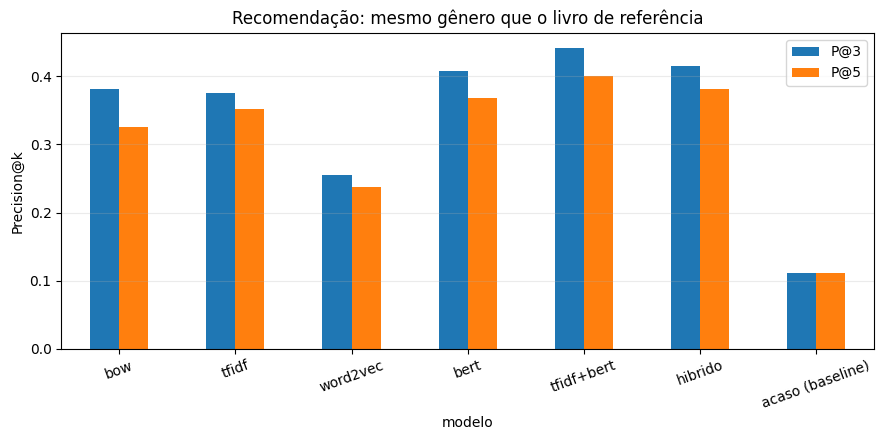

In [13]:
tabela = resultado.set_index('modelo')[['P@3', 'P@5']] ## Precisão nos top 3 e top 5
ax = tabela.plot(kind='bar', figsize=(9, 4.5), rot=20)
ax.set_ylabel('Precision@k')
ax.set_title('Recomendação: mesmo gênero que o livro de referência')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()